### **Examen Parcial**
#### **DRIVE**

Grupo 04\
Integrantes:
* Flores Baldoceda, Andres Francisco    20257600E
* Lazo Pampa, Victor Raul               20257639I
* Lopez Mendoza, Ruben                  20257664C
* Quispe Huanca, Juan Christian         20257661D

Paper: 
* "BRIEF: Binary Robust Independent Elementary Features" \
URL: https://link.springer.com/chapter/10.1007/978-3-642-15561-1_56

Data: 
* Trees (Blur), Graffiti (Viewpoint), Wall (Viewpoint), Ubc (JPEG Compression), Leuven (Light) \
https://www.robots.ox.ac.uk/~vgg/research/affine/

* Fountain (Viewpoint)
**PFL CVLAB Multi-View Dataset** (de Strecha et al.) \
https://github.com/openMVG/SfM_quality_evaluation/tree/348a981ef51112e9848acfb20004f4ed6fbc6ce3/Benchmarking_Camera_Calibration_2008/fountain-P11



In [1]:
%load_ext autoreload
%autoreload 2


#### **Importación de librerias**


In [2]:
# import os
# import glob
# import numpy as np 
# import cv2 
# import pandas as pd 

# import sys
from pathlib import Path
import matplotlib.pyplot as plt

# sys.path.append(str(Path(".").resolve()))
from src.data_loader import cargar_retina_image, cargar_mascara_gif, obtener_dataset_registros

from src.preprocessing import preprocesar_canal_verde, erosionar_mascara_fov

from src.metrics import calcular_matriz_confusion_fov, evaluar_segmentacion

from src.visualization import visualizar_resultado_pipeline

from src.pipelines import pipeline_a_adaptativo_sobel, pipeline_b_region_growing

#### **Fase 1:** *Carga de Datos y máscara FOV*


RGB Shape: (584, 565, 3), dtype: uint8
Verde Shape: (584, 565), dtype: uint8
Máscara FOV Shape: (584, 565), dtype: uint8


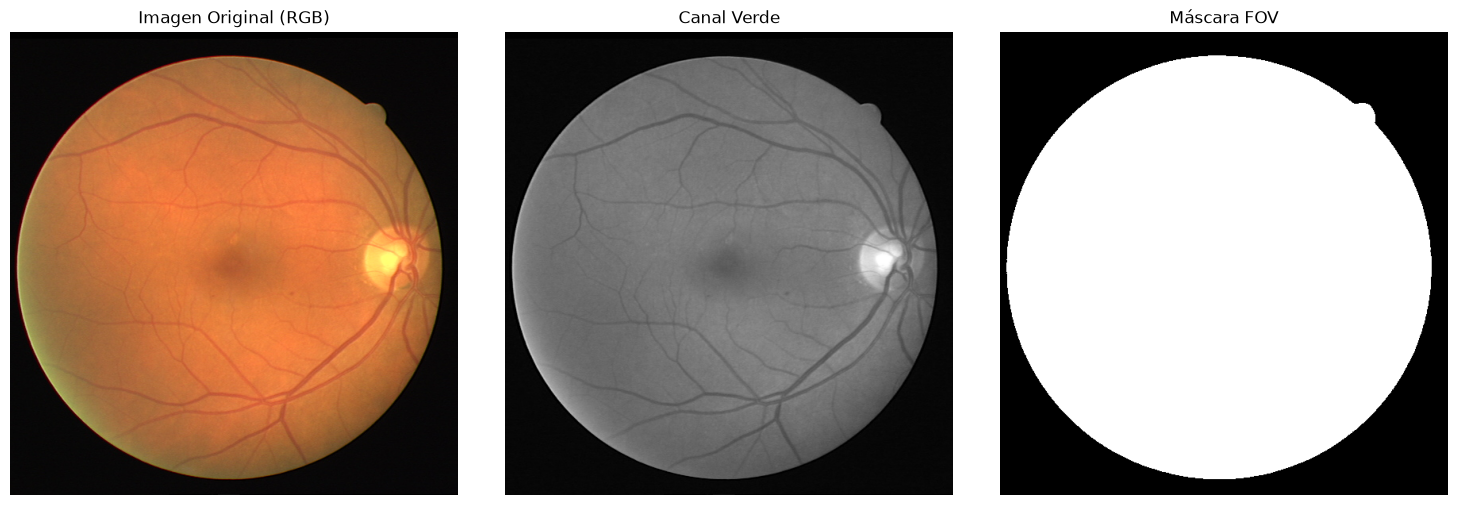

In [3]:
# Probando carga de archivos
img_path = Path("data/DRIVE/training/images/32_training.tif")
mask_path = Path("data/DRIVE/training/mask/32_training_mask.gif")

rgb_img, canal_verde = cargar_retina_image(img_path)

binario_mascara = cargar_mascara_gif(mask_path)

print(f"RGB Shape: {rgb_img.shape}, dtype: {rgb_img.dtype}")
print(f"Verde Shape: {canal_verde.shape}, dtype: {canal_verde.dtype}")
print(f"Máscara FOV Shape: {binario_mascara.shape}, dtype: {binario_mascara.dtype}")

# Visualización RGB y Canal verde
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_img)
axes[0].set_title("Imagen Original (RGB)")
axes[0].axis("off")

axes[1].imshow(canal_verde, cmap="gray")
axes[1].set_title("Canal Verde")
axes[1].axis("off")

axes[2].imshow(binario_mascara, cmap="gray")
axes[2].set_title("Máscara FOV")
axes[2].axis("off")

plt.tight_layout()
plt.show()




In [4]:
# 1. Probar en training (debe retornar 20 registros con manual_path válido)
train_records = obtener_dataset_registros("data/DRIVE", split="training")
print(f"Total imágenes de entrenamiento: {len(train_records)}")
print("Ejemplo registro 0:", train_records[0])
# 2. Probar en test (debe retornar 20 registros con manual_path = None)
test_records = obtener_dataset_registros("data/DRIVE", split="test")
print(f"Total imágenes de prueba (test): {len(test_records)}")
print("Ejemplo registro 0:", test_records[0])

Total imágenes de entrenamiento: 20
Ejemplo registro 0: {'id': '21', 'image_path': WindowsPath('data/DRIVE/training/images/21_training.tif'), 'fov_mask_path': WindowsPath('data/DRIVE/training/mask/21_training_mask.gif'), 'manual_path': WindowsPath('data/DRIVE/training/1st_manual/21_manual1.gif')}
Total imágenes de prueba (test): 20
Ejemplo registro 0: {'id': '01', 'image_path': WindowsPath('data/DRIVE/test/images/01_test.tif'), 'fov_mask_path': WindowsPath('data/DRIVE/test/mask/01_test_mask.gif'), 'manual_path': None}


#### **Fase 2:** *Preprocesamiento de imágenes*

dict_keys(['invertida', 'clahe', 'suavizada'])


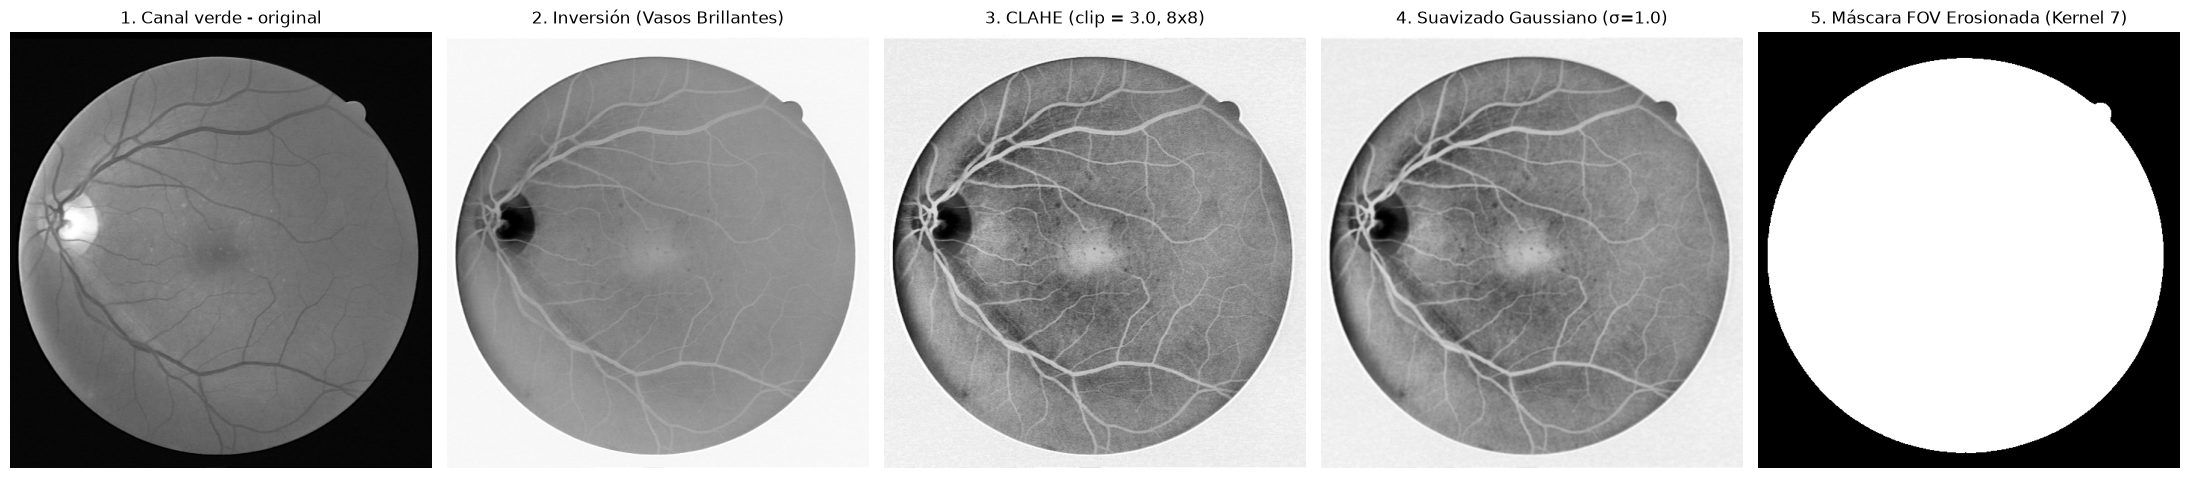

In [5]:
from matplotlib.pyplot import title
from IPython.core.pylabtools import figsize
train_registros = obtener_dataset_registros("data/DRIVE", split = "training")
muestra = train_registros[0]

rgb_img, canal_verde = cargar_retina_image(muestra['image_path'])
fov_mask = cargar_mascara_gif(muestra['fov_mask_path'])

prep_dict = preprocesar_canal_verde(
    canal_verde,
    clip_limit = 3.0,
    tile_grid_size = (8, 8),
    blur_ksize = 3.0, # pasar valor como entero y no 3.0
    blur_sigma = 1.0
)
fov_segura = erosionar_mascara_fov(fov_mask, tam_kernel = 7)

print(prep_dict.keys())

fig, axes = plt.subplots(1, 5, figsize = (22,5))

axes[0].imshow(canal_verde, cmap = 'gray')
axes[0].set_title("1. Canal verde - original")
axes[0].axis('off')

axes[1].imshow(prep_dict['invertida'], cmap = 'gray')
axes[1].set_title("2. Inversión (Vasos Brillantes)")
axes[1].axis('off')

axes[2].imshow(prep_dict['clahe'], cmap = 'gray')
axes[2].set_title("3. CLAHE (clip = 3.0, 8x8)")
axes[2].axis('off')

axes[3].imshow(prep_dict['suavizada'], cmap = 'gray')
axes[3].set_title("4. Suavizado Gaussiano (σ=1.0)")
axes[3].axis('off')

axes[4].imshow(fov_segura, cmap = 'gray')
axes[4].set_title("5. Máscara FOV Erosionada (Kernel 7)")
axes[4].axis('off')



plt.tight_layout()
plt.show()



# print(muestra)

#### **Fase 3:** *Implementación de pipeline*

Resultados Pipeline A -> Dice: 0.5934 | IoU: 0.4219 | Sensibilidad: 0.5372 | Especificidad: 0.9665
Prueba de Sanidad (Vacía vs GT) -> Dice: 0.0000, Sensibilidad: 0.0000


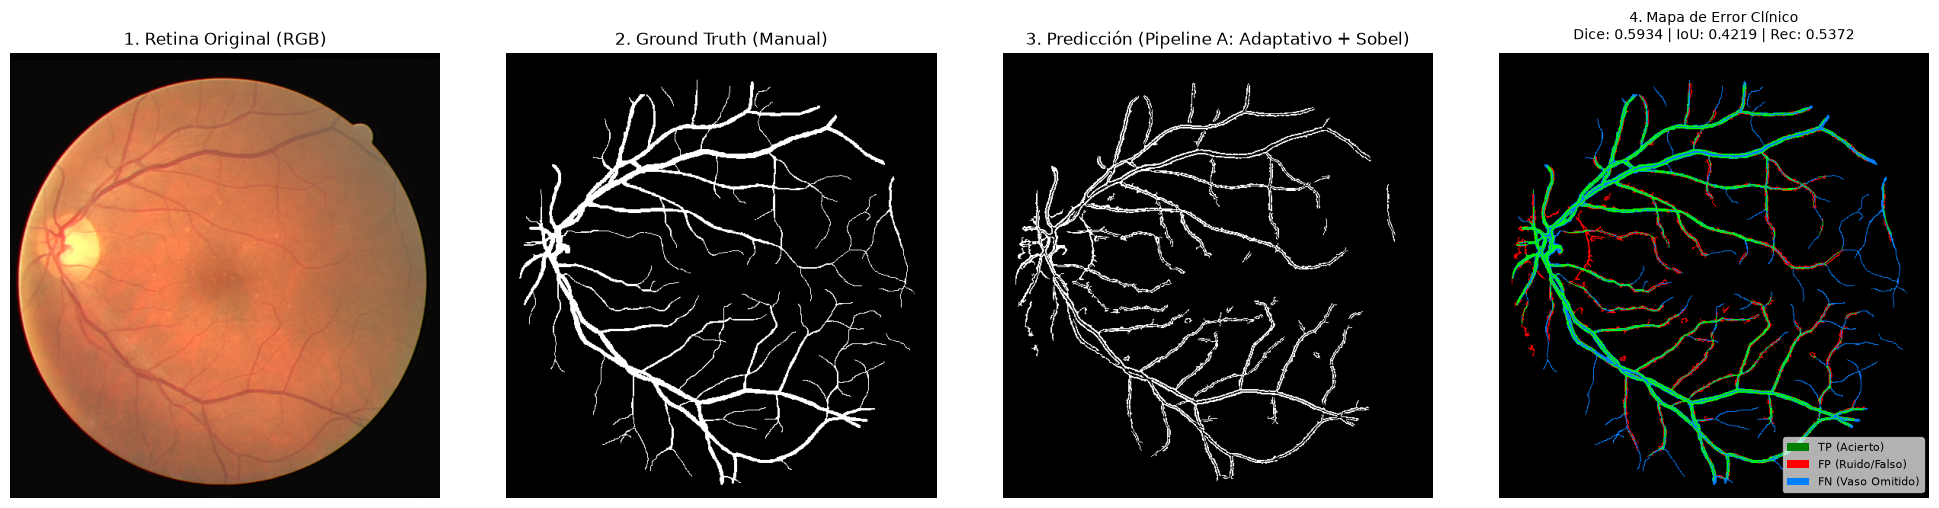

In [6]:
# Pipeline A:
import numpy as np

registros = obtener_dataset_registros("data/DRIVE", split ="training")
muestra = registros[0]

rgb_img, canal_verde = cargar_retina_image(muestra['image_path'])

gt = cargar_mascara_gif(muestra['manual_path'])
fov = cargar_mascara_gif(muestra['fov_mask_path'])

prep_dict = preprocesar_canal_verde(canal_verde)
fov_segura =  erosionar_mascara_fov(fov, tam_kernel = 7)

pred_a = pipeline_a_adaptativo_sobel(
    prep_dict['suavizada'],
    fov_segura,
    block_size = 19,
    c_offset = 1.0, # 2.0
    sobel_threshold = 18, # Era 30 lo estamos disminuyendo a 18
    min_area = 25
    )

metricas_a = evaluar_segmentacion(pred_a, gt, fov)
print(f"Resultados Pipeline A -> Dice: {metricas_a['dice']:.4f} | IoU: {metricas_a['iou']:.4f} | Sensibilidad: {metricas_a['sensibilidad']:.4f} | Especificidad: {metricas_a['especificidad']:.4f}")


mascara_vacia = np.zeros_like(gt)
metricas_vacias = evaluar_segmentacion(mascara_vacia, gt, fov)
print(f"Prueba de Sanidad (Vacía vs GT) -> Dice: {metricas_vacias['dice']:.4f}, Sensibilidad: {metricas_vacias['sensibilidad']:.4f}")


visualizar_resultado_pipeline(
    rgb_img, 
    gt, 
    pred_a, 
    fov, 
    metricas = metricas_a,
    titulo_pipeline = "Pipeline A: Adaptativo + Sobel"
)

# 5.1 Análisis de sensibilidad

# 5.2 mapa de error visual
# Pipeline B:
# Pipeline C:
# Pipeline D:

Resultados Pipeline B -> Dice: 0.7398 | IoU: 0.5870 | Sensibilidad: 0.8170 | Especificidad: 0.9519


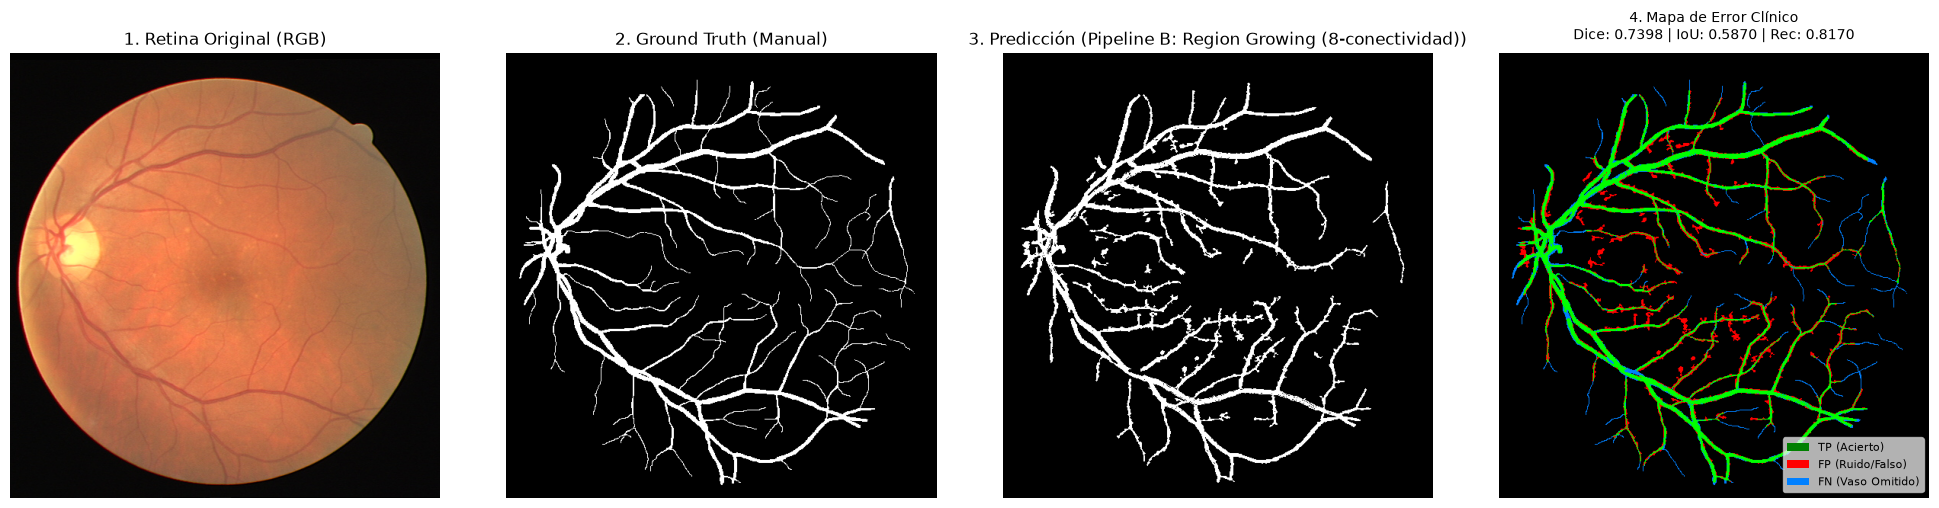

In [3]:
# Pipeline B
# 1. Cargar datos del primer registro de entrenamiento (ID: 21)
registros = obtener_dataset_registros("data/DRIVE", split="training")
muestra = registros[0]
rgb_img, canal_verde = cargar_retina_image(muestra['image_path'])
gt = cargar_mascara_gif(muestra['manual_path'])
fov = cargar_mascara_gif(muestra['fov_mask_path'])

# 2. Preprocesamiento óptico y erosión de seguridad del FOV
prep_dict = preprocesar_canal_verde(canal_verde)
fov_segura = erosionar_mascara_fov(fov, tam_kernel=7)

# 3. Ejecutar Pipeline B con parámetros calibrados (Semillas Otsu + 8-Conectividad)
pred_b = pipeline_b_region_growing(
    prep_dict['suavizada'],
    fov_segura,
    radio_disco=11,        # Elemento estructurante elíptico acorde al ancho máximo de vaso
    factor_semilla=1.0,    # Multiplicador sobre el umbral de Otsu para semillas ultra puras
    lo_diff=15,             # Tolerancia inferior del predicado Q para evitar desborde al fondo
    up_diff=15,             # Tolerancia superior del predicado Q
    min_area=25            # Poda de componentes aisladas de ruido
)


# 4. Evaluación de Métricas dentro del FOV
metricas_b = evaluar_segmentacion(pred_b, gt, fov)
print(f"Resultados Pipeline B -> Dice: {metricas_b['dice']:.4f} | IoU: {metricas_b['iou']:.4f} | Sensibilidad: {metricas_b['sensibilidad']:.4f} | Especificidad: {metricas_b['especificidad']:.4f}")

# 5. Visualización del Panel Comparativo y Mapa de Error Clínico
visualizar_resultado_pipeline(
    rgb_img, 
    gt, 
    pred_b, 
    fov, 
    metricas=metricas_b,
    titulo_pipeline="Pipeline B: Region Growing (8-conectividad)"
)

#### **Fase 4:** *Postprocesamiento y limpieza morfológica*

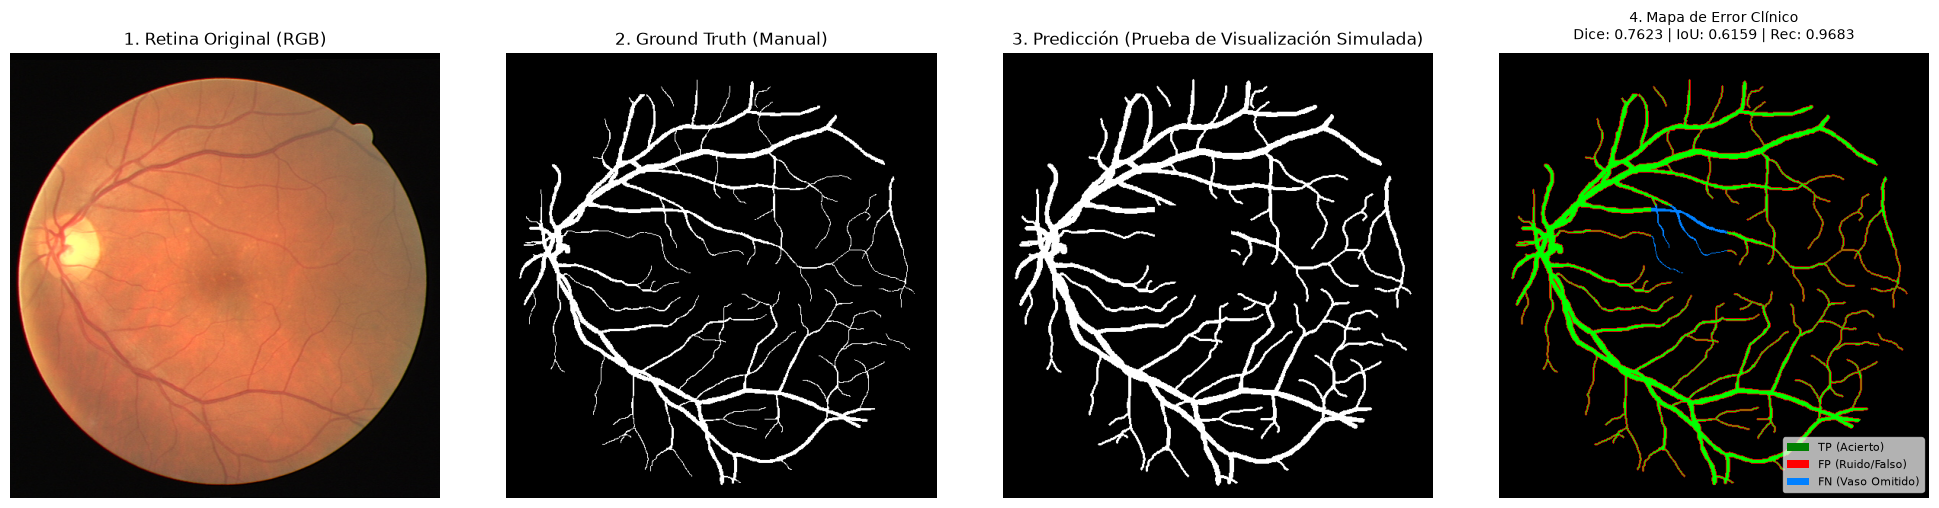

In [8]:
import cv2

registros = obtener_dataset_registros("data/DRIVE", split ="training")

# print(list(train_registros[0].keys()))
muestra = registros[0]

rgb_img, _ = cargar_retina_image(muestra['image_path'])
gt = cargar_mascara_gif(muestra['manual_path'])
fov = cargar_mascara_gif(muestra['fov_mask_path'])

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
pred_simulada = cv2.dilate(gt, kernel, iterations = 1)
pred_simulada[200:300, 200:300] = 0 # Provocamos una zona omisión, para que los vasos se piten de azul
                                    # cuadrado de la fila 200 a la 300 y de la columna 200 a 300, colocando 0 (negro)


metricas = evaluar_segmentacion(pred_simulada, gt, fov)
visualizar_resultado_pipeline(
    rgb_img,
    gt,
    pred_simulada,
    fov,
    metricas = metricas, 
    titulo_pipeline = "Prueba de Visualización Simulada"
)


#### **Fase 5:** *Evaluación y métricas*

In [9]:
import numpy as np

train_registros = obtener_dataset_registros("data/DRIVE", split ="training")
# print(list(train_registros[0].keys()))

gt = cargar_mascara_gif(train_registros[0]['manual_path'])
fov = cargar_mascara_gif(train_registros[0]['fov_mask_path'])

metricas_perfectas = evaluar_segmentacion(gt, gt, fov)
print(f"Prueba de Sanidad (GT vs GT) -> Dice: {metricas_perfectas['dice']:.4f}, IoU: {metricas_perfectas['iou']:.4f}")
assert np.isclose(metricas_perfectas['dice'], 1.0), "Error : Dice debería ser 1.0"

mascara_vacia = np.zeros_like(gt)
metricas_vacias = evaluar_segmentacion(mascara_vacia, gt, fov)
print(f"Prueba de Sanidad (Vacía vs GT) -> Dice: {metricas_vacias['dice']:.4f}, Sensibilidad: {metricas_vacias['sensibilidad']:.4f}")


print(metricas_perfectas.keys())

# 5.1 Análisis de sensibilidad

# 5.2 mapa de error visual

Prueba de Sanidad (GT vs GT) -> Dice: 1.0000, IoU: 1.0000
Prueba de Sanidad (Vacía vs GT) -> Dice: 0.0000, Sensibilidad: 0.0000
dict_keys(['dice', 'iou', 'sensibilidad', 'especificidad', 'accuracy', 'tp', 'fp', 'tn', 'fn'])


#### **Fase 6:** *Ejecución experimental y almacenamiento*

#### **Conclusiones y Análisis de resultados**